PROJECT - Air Quality Across Six Indian Monitoring Sites: Patterns, Seasonality, and Data Limitations (2019–2025)

In [40]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

The libraries have been imported successfully.

In [41]:
sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind"
)


In [42]:

import glob
import os

files = glob.glob("../data/raw/*.csv")
dataframes = []

for file in files:
    df = pd.read_csv(file, na_values="NA")
    df["Timestamp"] = pd.to_datetime(
    df["Timestamp"],
    errors="coerce",
    format="mixed"
)


    filename = os.path.basename(file).lower()
    df["source_file"] = os.path.basename(file)
    if "site_5115" in filename:
        df["station"] = "Worli, Mumbai"
    elif "site_306" in filename:
        df["station"] = "Manali, Chennai"
    elif "site_301" in filename:
        df["station"] = "Anand Vihar, Delhi"
    elif "site_296" in filename:
        df["station"] = "Rabindra Bharati University, Kolkata"
    elif "site_162" in filename:
        df["station"] = "BTM Layout, Bengaluru"
    elif "site_134" in filename:
        df["station"] = "Police Commissionerate, Jaipur"

    dataframes.append(df)

data = pd.concat(dataframes, ignore_index=True)

print("Missing timestamps:", data["Timestamp"].isna().sum())
data.head()


Missing timestamps: 0


,Timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),...,RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s),source_file,station
0,2019-01-01,116.80,223.61,122.80,62.36,135.58,20.46,22.25,1.09,28.54,...,38.08,0.51,145.75,NaN,NaN,99.52,763.94,0.15,Raw_Data_2019_site_134_police_commissionerate_...,"Police Commissionerate, Jaipur"
1,2019-01-02,99.42,201.11,111.89,64.39,123.16,21.34,18.79,1.18,24.97,...,37.36,0.53,147.59,NaN,NaN,111.43,763.81,0.07,Raw_Data_2019_site_134_police_commissionerate_...,"Police Commissionerate, Jaipur"
2,2019-01-03,109.84,171.40,38.85,79.42,72.59,25.99,34.95,0.85,20.01,...,35.69,0.61,185.49,NaN,NaN,113.11,765.04,-0.01,Raw_Data_2019_site_134_police_commissionerate_...,"Police Commissionerate, Jaipur"
3,2019-01-04,87.10,153.65,34.62,69.28,59.14,25.58,54.86,0.82,17.15,...,37.80,0.70,109.16,NaN,NaN,94.63,763.85,0.08,Raw_Data_2019_site_134_police_commissionerate_...,"Police Commissionerate, Jaipur"
4,2019-01-05,67.49,134.12,3.96,49.68,28.69,23.20,12.92,0.83,32.59,...,43.14,1.30,81.79,NaN,NaN,97.42,762.02,0.20,Raw_Data_2019_site_134_police_commissionerate_...,"Police Commissionerate, Jaipur"


The data has been loaded correctly.

In [43]:
data["year"] = data["Timestamp"].dt.year
data["month"] = data["Timestamp"].dt.month

station_order = [
    "Anand Vihar, Delhi",
    "BTM Layout, Bengaluru",
    "Manali, Chennai",
    "Police Commissionerate, Jaipur",
    "Rabindra Bharati University, Kolkata",
    "Worli, Mumbai"
]

In [44]:
data["station"].value_counts()

station
Police Commissionerate, Jaipur          2557
BTM Layout, Bengaluru                   2557
Rabindra Bharati University, Kolkata    2557
Anand Vihar, Delhi                      2557
Manali, Chennai                         2557
Worli, Mumbai                           2557
Name: count, dtype: int64

In [45]:
print("Rows and columns:", data.shape)
print("Date range:", data["Timestamp"].min(), "to", data["Timestamp"].max())
print("Missing values by column:")
print(data.isnull().sum())
print("Duplicate station-date rows:",
      data.duplicated(["station", "Timestamp"]).sum())

Rows and columns: (15342, 29)
Date range: 2019-01-01 00:00:00 to 2025-12-31 00:00:00
Missing values by column:
Timestamp                  0
PM2.5 (µg/m³)            784
PM10 (µg/m³)            2264
NO (µg/m³)               916
NO2 (µg/m³)              851
NOx (ppb)                777
NH3 (µg/m³)             1650
SO2 (µg/m³)              731
CO (mg/m³)               737
Ozone (µg/m³)           1558
Benzene (µg/m³)         2111
Toluene (µg/m³)         4282
Xylene (µg/m³)         15342
O Xylene (µg/m³)       15342
Eth-Benzene (µg/m³)     6894
MP-Xylene (µg/m³)       5863
AT (°C)                 9331
RH (%)                   687
WS (m/s)                 838
WD (deg)                 837
RF (mm)                14028
TOT-RF (mm)             7671
SR (W/mt2)              1133
BP (mmHg)               3420
VWS (m/s)               5431
source_file                0
station                    0
year                       0
month                      0
dtype: int64
Duplicate station-date rows: 0


In [46]:
df["source_file"] = os.path.basename(file)

In [47]:
data.groupby("station")[["PM2.5 (µg/m³)", "PM10 (µg/m³)"]].count()

,PM2.5 (µg/m³),PM10 (µg/m³)
station,,
"Anand Vihar, Delhi",2490,2475
"BTM Layout, Bengaluru",2409,1700
"Manali, Chennai",2416,1658
"Police Commissionerate, Jaipur",2530,2532
"Rabindra Bharati University, Kolkata",2498,2496
"Worli, Mumbai",2215,2217


In [48]:
data["year"] = data["Timestamp"].dt.year

coverage_by_year = data.groupby(["station", "year"])[
    ["PM2.5 (µg/m³)", "PM10 (µg/m³)"]
].count()

coverage_by_year

PM2.5 (µg/m³)  PM10 (µg/m³)
station                              year                             
Anand Vihar, Delhi                   2019            365           357
                                     2020            336           336
                                     2021            362           359
                                     2022            365           365
                                     2023            355           352
                                     2024            344           342
                                     2025            363           364
BTM Layout, Bengaluru                2019            352             0
                                     2020            356             4
                                     2021            322           325
                                     2022            352           352
                                     2023            360           359
                                     2024            307           309
                                     2025            360           351
Manali, Chennai                      2019            310             0
                                     2020            366             0
                                     2021            361           256
                                     2022            363           363
                                     2023            354           356
                                     2024            355           353
                                     2025            307           330
Police Commissionerate, Jaipur       2019            365           365
                                     2020            366           366
                                     2021            363           363
                                     2022            356           356
                                     2023            355           356
                                     2024            365           365
                                     2025            360           361
Rabindra Bharati University, Kolkata 2019            354           357
                                     2020            339           332
                                     2021            361           362
                                     2022            353           353
                                     2023            363           363
                                     2024            365           365
                                     2025            363           364
Worli, Mumbai                        2019            204           204
                                     2020            345           354
                                     2021            344           308
                                     2022            341           334
                                     2023            306           354
                                     2024            352           342
                                     2025            323           321

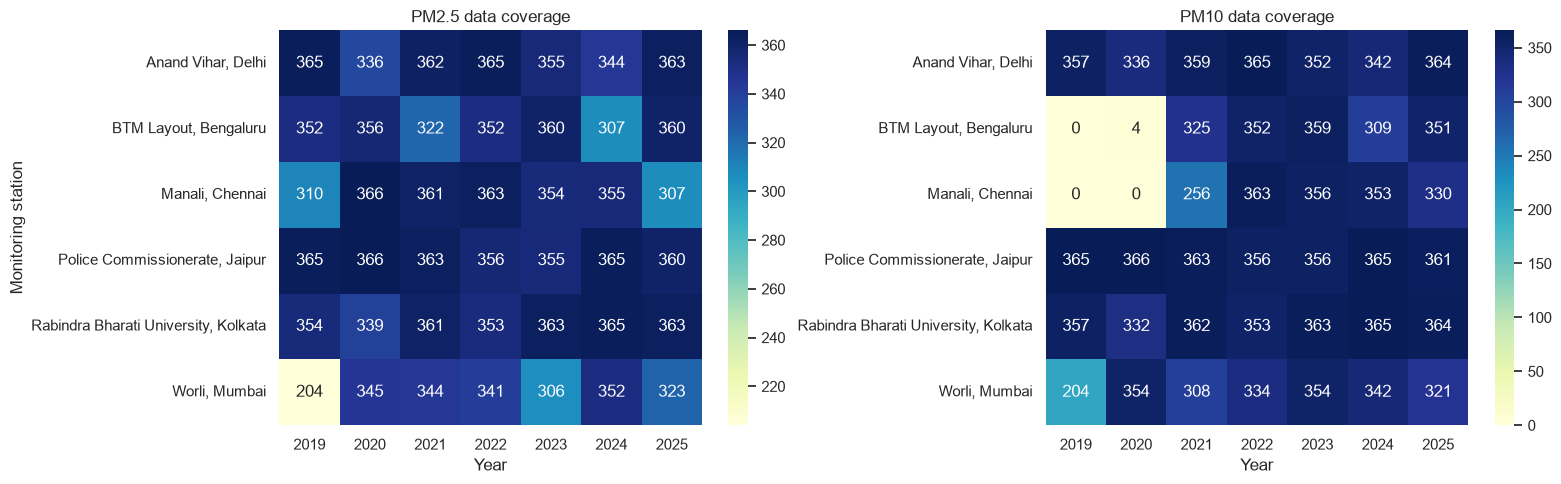

In [49]:
pm25_counts = data.pivot_table(
    index="station",
    columns="year",
    values="PM2.5 (µg/m³)",
    aggfunc="count"
).reindex(station_order)

pm10_counts = data.pivot_table(
    index="station",
    columns="year",
    values="PM10 (µg/m³)",
    aggfunc="count"
).reindex(station_order)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.heatmap(pm25_counts, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("PM2.5 data coverage")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Monitoring station")

sns.heatmap(pm10_counts, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("PM10 data coverage")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

The two heatmaps count valid daily PM2.5 and PM10 readings for each monitoring station and year. A full year has 365 or 366 days, so counts near that range indicate strong date coverage

Data coverage is generally strong for PM2.5, but PM10 has major early gaps at Bengaluru and Manali. Bengaluru recorded only 0 and 4 valid PM10 days in 2019 and 2020, while Manali recorded 0, 0, and 256 days from 2019–2021. These incomplete records are not reliable for direct annual comparison. Mumbai’s 2019 coverage is also lower than later years. Therefore,all years cannot be treated as equal representative.


In [50]:
pm25 = data.dropna(subset=["PM2.5 (µg/m³)"])

fig = px.violin(
    pm25,
    x="station",
    y="PM2.5 (µg/m³)",
    color="station",
    box=True,
    title="Daily PM2.5  Distribution by Monitoring Station",
    labels={
        "station": "Monitoring station",
        "PM2.5 (µg/m³)": "Daily PM2.5 (µg/m³)"
    }
)

fig.add_hline(y=60, line_dash="dash", line_color="red")
fig.add_hline(y=15, line_dash="dot", line_color="green")
fig.update_layout(showlegend=False)
fig.show()

In the above chart, the red line marks India’s 24-hour PM2.5 standard of 60 µg/m³. The green line marks WHO’s 24-hour guideline of 15 µg/m³.

In the above chart,PM2.5 readings are concentrated at lower levels but have long upper tails, showing that occasional high-pollution days are an important part of the record. Anand Vihar in Delhi has the broadest and most extreme distribution, while Bengaluru, Chennai, and Worli have lower-centered distributions. All six stations show readings above the WHO reference, and each has readings above India’s daily standard, showing that extreme readings occurred across the study sites and that high-pollution episodes are not unique to Anand Vihar; they appear in every selected station’s record.This also indicates a multi-location air-quality concern within the different regions in our country.

In [51]:
from typing import Any


annual = data.groupby(["station", "year"])[
    ["PM2.5 (µg/m³)", "PM10 (µg/m³)", ]
].median().reset_index()

fig = go.Figure()

for station in station_order:
    station_data = annual[annual["station"] == station]

    fig.add_scatter(
        x=station_data["year"],
        y=station_data["PM2.5 (µg/m³)"],
        mode="lines+markers",
        name=station
    )

for station in station_order:
    station_data = annual[annual["station"] == station]

    fig.add_scatter(
        x=station_data["year"],
        y=station_data["PM10 (µg/m³)"],
        mode="lines+markers",
        name=station,
        visible=False
    )

fig.update_layout(
    title="Annual Median Pollution by Monitoring Station",
    xaxis_title="Year",
    yaxis_title="PM2.5 median (µg/m³)",
    updatemenus=[{
        "buttons": [
            {
                "label": "PM2.5",
                "method": "update",
                "args": [
                    {"visible": [True] * 6 + [False] * 6},
                    {"yaxis.title": "PM2.5 median (µg/m³)"}
                ]
            },
            {
                "label": "PM10",
                "method": "update",
                "args": [
                    {"visible": [False] * 6 + [True] * 6},
                    {"yaxis.title": "PM10 median (µg/m³)"}
                ]
            }
        ],
        "direction": "down"
    }]
)

fig.show()

 The chart plots each monitoring station’s annual median PM2.5 from 2019 to 2025. We can use the dropdown to switch pollutants; the image shows PM2.5.
 1. for PM2.5, annual median followed different paths across the six monitoring stations. Delhi remained highest, peaking in 2022 and then declining; Bengaluru, Chennai, Jaipur, and Kolkata ended below their 2019 medians, while Mumbai ended higher. The year-to-year fluctuations mean the chart does not support one uniform “air is getting cleaner” conclusion. ALso Mumbai’s 2019 comparison needs caution because its data coverage was lower that year.  

 2. For PM10, annual median differs sharply across the monitoring stations. Anand Vihar, Delhi, remains highest, rising to a peak around 2022 before declining by 2025; Jaipur is generally the next highest. Bengaluru and Chennai have lower values in the years shown, but missing early records limit their trend comparisons. Overall, the chart shows station-specific fluctuations rather than one shared, steady improvement


In [52]:
monthly = data.groupby(["station", "month"])[
    ["PM2.5 (µg/m³)", "PM10 (µg/m³)"]
].median().reset_index()

fig = go.Figure()

for pollutant in ["PM2.5 (µg/m³)", "PM10 (µg/m³)"]:
    chart_data = monthly.pivot(
        index="station",
        columns="month",
        values=pollutant
    ).reindex(station_order)

    fig.add_trace(go.Heatmap(
        z=chart_data.values,
        x=chart_data.columns,
        y=chart_data.index,
        colorscale="YlGnBu",
        visible=(pollutant == "PM2.5 (µg/m³)")
    ))

fig.update_layout(
    title="Monthly Pollution by Monitoring Station",
    updatemenus=[{
        "buttons": [
            {
                "label": "PM2.5",
                "method": "update",
                "args": [
                    {"visible": [True, False]},
                    {"title": "Monthly Median PM2.5  by Monitoring Station"}
                ]
            },
            {
                "label": "PM10",
                "method": "update",
                "args": [
                    {"visible": [False, True]},
                    {"title": "Monthly Median PM10 by Monitoring Station"}
                ]
            }
        ],
        "direction": "down"
    }]
)

fig.show()
         

The heatmap compares each station’s typical monthly concentration. The dropdown is set to PM2.5(can be changed), and darker blue cells show higher medians.
1. For PM2.5, the monthly heatmap shows a strong seasonal contrast in PM2.5 at Anand Vihar, Delhi: medians are highest at the beginning and end of the year and lower through much of the middle months. Kolkata shows a similar, though less pronounced, pattern, while Bengaluru’s monthly levels are comparatively low and even. This calendar view helps identify when pollution tends to be higher, but it does not explain the causes. 

2. for PM10, across the monitoring stations, monthly median PM10 is generally higher near the beginning and end of the year and lower around midyear. Anand Vihar, Delhi, shows the strongest seasonal contrast, while Bengaluru and Chennai remain comparatively low and even. Combining years makes these recurring monthly differences easier to compare; the heatmap shows when PM10 tends to rise, but not why.


In [53]:
stations = data["station"].unique()
fig = go.Figure()

for station in stations:
    city_data = data[data["station"] == station]
    heatmap_data = city_data.pivot_table(
        index="year",
        columns="month",
        values="PM10 (µg/m³)",
        aggfunc="median"
    )

    fig.add_trace(go.Heatmap(
        z=heatmap_data.values,
        x=heatmap_data.columns,
        y=heatmap_data.index,
        colorscale="YlGnBu",
        visible=(station == stations[0])
    ))

fig.update_layout(
    title="Monthly PM10 by Year",
    xaxis_title="Month",
    yaxis_title="Year",
    updatemenus=[{
        "buttons": [
            {
                "label": station,
                "method": "update",
                "args": [
                    {"visible": [s == station for s in stations]},
                    {"title": f"Monthly PM10 by Year — {station}"}
                ]
            }
            for station in stations
        ],
        "direction": "down",
        "x": 0,
        "y": 1.15
    }]
)

fig.show()

 
This chart combines years into one monthly pattern. 
It separates years, revealing that the seasonal peaks vary in strength and timing rather than repeating at one fixed level.

1. In Jaipur, monthly median PM10 is generally lower during July–September and rises again toward the end of the year. The late-year increase varies considerably: November is especially high in 2021, 2023, and 2024. Separating months by year shows that seasonal peaks are not equally strong every year, which would be hidden by a heatmap that averages across all years. 

2. Bengaluru’s monthly PM10 pattern varies considerably across years. The heatmap shows a sharp February peak in 2021 and broadly higher readings during the first half of 2022, while 2023 is lower across much of the year. This suggests the timing and strength of peaks are not consistent from year to year. The 2020 record is almost entirely missing, and 2024 has gaps, so those years cannot support complete seasonal comparisons.

3. Kolkata’s monthly median PM10 is generally higher at the beginning and end of the year and lower through much of the middle months. This seasonal pattern is strongest in 2019–2022, while the heatmap shows lower readings across much of 2024–2025. The chart reveals both a recurring monthly cycle and year-to-year differences, but coverage should be checked before interpreting the later values as a sustained improvement. 

4. At Anand Vihar, monthly median PM10 is generally higher toward the end of the year, with strong October–November values across several years. Midyear months, especially July and August, tend to be lower. The strength of the late-year increase varies by year, so this chart reveals a recurring seasonal pattern rather than a fixed level or its cause. 

5. Manali’s monthly median PM10 varies by both season and year. The clearest feature is a sharp 2025 increase in January, February, and December, while readings from March through November are mostly lower. This points to concentrated winter-month peaks rather than a year-round increase. The pattern needs to be interpreted cautiously because the chart covers only 2021–2025, and January–February 2021 are missing. 

6. At Worli, monthly median PM10 is generally higher around November–February and lower during much of May–September. The winter peak varies by year: it is especially strong in 2021–2022, while 2024 shows a notable rise in November and December. This chart reveals a recurring seasonal pattern whose intensity changes from year to year. The 2019 record is missing January–May, so that year cannot be compared across all months.


summary:Across the heatmaps shared so far, PM10 is often higher toward the beginning or end of the year and lower during midyear months, but the pattern and peak months vary by city and year. Some years also have missing months, so incomplete rows need caution when comparing seasonal pattern




In [54]:
fig = go.Figure()

for pollutant in ["PM2.5 (µg/m³)", "PM10 (µg/m³)"]:
    for station in station_order:
        values = data.loc[
            data["station"] == station, pollutant
        ].dropna()

        fig.add_trace(go.Box(
            y=values,
            name=station,
            visible=(pollutant == "PM2.5 (µg/m³)")
        ))

fig.update_layout(
    title="Pollution Levels by Monitoring Station",
    yaxis_title="PM2.5 (µg/m³)",
    xaxis_title="Monitoring station",
    updatemenus=[{
        "buttons": [
            {
                "label": "PM2.5",
                "method": "update",
                "args": [
                    {"visible": [True] * 6 + [False] * 6},
                    {"title": "PM2.5 Levels by Monitoring Station",
                     "yaxis.title": "PM2.5 (µg/m³)"}
                ]
            },
            {
                "label": "PM10",
                "method": "update",
                "args": [
                    {"visible": [False] * 6 + [True] * 6},
                    {"title": "PM10 Levels by Monitoring Station",
                     "yaxis.title": "PM10 (µg/m³)"}
                ]
            }
        ],
        "direction": "down"
    }]
)

fig.show()

From the above chart it can be inferred that:(using the dropdown)
1. Daily PM2.5 levels differ across the six cities. Delhi has the highest median and widest middle range, so its typical readings are higher and more variable. Kolkata and Jaipur also show many high-pollution outliers, while Bengaluru, Chennai, and Mumbai have lower medians but still experience occasional spikes. This box plot helps rank the cities by typical pollution and shows how much daily readings vary; the pollutant dropdown lets the same comparison be repeated for other pollutants in the data.

2. PM10 distributions differ substantially across the six monitoring stations. Anand Vihar, Delhi, has the highest median and widest middle range, indicating both higher typical readings and greater variation. Kolkata and Jaipur also show broad distributions and many high-reading days. Bengaluru, Chennai, and Mumbai have lower medians, although each has occasional spikes. This comparison shows that both typical PM10 levels and day-to-day variability differ across stations.

In [55]:
data["Timestamp"] = pd.to_datetime(data["Timestamp"])
data["year"] = data["Timestamp"].dt.year
data["month"] = data["Timestamp"].dt.month
data["day"] = data["Timestamp"].dt.day

lockdown_data = data[
    data["year"].isin([2019, 2020, 2021])
    & (
        ((data["month"] == 3) & (data["day"] >= 25))
        | (data["month"].isin([4, 5]))
    )
]

summary = lockdown_data.groupby(["station", "year"])[
    "PM2.5 (µg/m³)"
].mean().reset_index()

fig = go.Figure()

colors = {2019: "#4C78A8", 2020: "#F58518", 2021: "#54A24B"}

for year in [2019, 2020, 2021]:
    year_data = summary[summary["year"] == year]

    fig.add_bar(
        x=year_data["station"],
        y=year_data["PM2.5 (µg/m³)"],
        name=str(year),
        marker_color=colors[year]
    )

fig.update_layout(
    title="PM2.5 During the Same Dates Across 2019, 2020, and 2021",
    xaxis_title="Monitoring station",
    yaxis_title="Mean PM2.5 (µg/m³)",
    barmode="group",
)

fig.show()

From the above bar chart, it is observed that during March 25–May 31, mean PM2.5 was lower in 2020 than in 2019 at every station with both values shown. In 2021, it increased from 2020 at five stations, while Bengaluru remained slightly lower.Delhi had the highest mean across the three years. This pattern is consistent with a lockdown-period decrease,followed by a partial rebound, but it does not establish lockdown as the sole cause for it.


In [56]:
diwali_dates = {
    2019: "2019-10-27",
    2020: "2020-11-14",
    2021: "2021-11-04",
    2022: "2022-10-24",
    2023: "2023-11-12",
    2024: "2024-10-31",
    2025: "2025-10-20"
}

data["Timestamp"] = pd.to_datetime(data["Timestamp"])

stations = sorted(data["station"].dropna().unique())
years = list(diwali_dates)

fig = go.Figure()

for year in years:
    festival_day = pd.to_datetime(diwali_dates[year])

    for station in stations:
        station_data = data[
            (data["station"] == station)
            & (data["Timestamp"] >= festival_day - pd.Timedelta(days=7))
            & (data["Timestamp"] <= festival_day + pd.Timedelta(days=7))
        ].copy()

        station_data["days_from_diwali"] = (
            station_data["Timestamp"] - festival_day
        ).dt.days

        fig.add_scatter(
            x=station_data["days_from_diwali"],
            y=station_data["PM2.5 (µg/m³)"],
            mode="lines+markers",
            name=station,
            visible=(year == years[0] and station == stations[0])
        )

buttons = []

for year in years:
    for station in stations:
        visible = [
            trace_year == year and trace_station == station
            for trace_year in years
            for trace_station in stations
        ]

        buttons.append({
            "label": f"{year} — {station}",
            "method": "update",
            "args": [
                {"visible": visible},
                {"title": f"PM2.5 Around Diwali — {station} — {year}"}
            ]
        })

fig.update_layout(
    title=f"PM2.5 Around Diwali — {stations[0]} — {years[0]}",
    xaxis_title="Days from Diwali",
    yaxis_title="PM2.5 (µg/m³)",
    updatemenus=[{
        "buttons": buttons,
        "direction": "down"
    }]
)

fig.add_vline(x=0, line_dash="dash", line_color="red")
fig.show()

From the above chart, using drop-down, the following can be inferred.


1. THe charts show PM2.5 for each monitoring site from 7 days before to 7 days after Diwali. There is a comparison of  the visible patterns around Diwali across 2019–2025. These plots show association around the festival date.

2. The clearest takeaway is that the post-Diwali pattern is not the same at every site or every year. Anand Vihar, Delhi, shows some of the strongest PM2.5 levels in the set, including high values around Diwali in several years. Other sites, such as BTM Layout and Worli, are on much lower chart scales.

3. The charts suggest a visible rise near or after Diwali in some site-year panels, but they do not show a uniform spike across all six sites. Some panels have little change or unclear movement.

4. Conclusion: Diwali-period PM2.5 appears to vary substantially by location and year. The event-window chart is useful for spotting possible short-term changes, but a stronger conclusion needs exact daily values, enough observations before and after the festival, and a defined comparison with quieter nearby days. It cannot establish that fireworks or restrictions caused the observed patterns.

The following can be summarised from the above points:

PM2.5 around Diwali did not follow one consistent pattern across the six monitoring sites and years shown. Anand Vihar, Delhi, reached especially high levels in several panels, while other sites showed smaller or less clear changes. Because the plots use different vertical scales, comparisons focus on each site’s change around Diwali rather than raw heights across sites. These event-window patterns suggest possible local, year-specific increases, but the charts alone cannot attribute them to fireworks or measure a causal effect. 



In [57]:
variables = [
    "PM2.5 (µg/m³)",
    "PM10 (µg/m³)",
    "NO2 (µg/m³)",
    "NO (µg/m³)",
    "NOx (ppb)",
    "NH3 (µg/m³)",
    "SO2 (µg/m³)",
    "CO (mg/m³)",
    "Ozone (µg/m³)",
    "Benzene (µg/m³)",
    "Toluene (µg/m³)",
    "Xylene (µg/m³)",
    "AT (°C)",
    "RH (%)",
    "WS (m/s)"
]

stations = sorted(data["station"].dropna().unique())
fig = go.Figure()

for station in stations:
    station_data = data[data["station"] == station]
    correlations = station_data[variables].corr()

    fig.add_heatmap(
        z=correlations.values,
        x=variables,
        y=variables,
        zmin=-1,
        zmax=1,
        colorscale="RdBu",
        visible=(station == stations[0])
    )

fig.update_layout(
    title=f"Pollutant Correlations — {stations[0]}",
    updatemenus=[{
        "buttons": [
            {
                "label": station,
                "method": "update",
                "args": [
                    {"visible": [name == station for name in stations]},
                    {"title": f"Pollutant Correlations — {station}"}
                ]
            }
            for station in stations
        ],
        "direction": "down",
        "x": 0,
        "y": 1.15
    }],
    xaxis_title="",
    yaxis_title=""
)

fig.show()

for station in data["station"].dropna().unique():
    station_data = data[data["station"] == station]
    correlations = station_data[variables].corr()

    pairs = correlations.where(
        np.triu(np.ones(correlations.shape), k=1).astype(bool)
    ).stack()

    print(f"\n{station}")
    print("Strongest positive:")
    print(pairs.sort_values(ascending=False).head(5))
    print("Strongest negative:")
    print(pairs.sort_values().head(5))


Police Commissionerate, Jaipur
Strongest positive:
NO (µg/m³)       NOx (ppb)          0.928432
PM2.5 (µg/m³)    PM10 (µg/m³)       0.840028
Benzene (µg/m³)  Toluene (µg/m³)    0.837191
NO2 (µg/m³)      NOx (ppb)          0.724668
NH3 (µg/m³)      AT (°C)            0.539312
dtype: float64
Strongest negative:
Ozone (µg/m³)  AT (°C)    -0.492194
NOx (ppb)      WS (m/s)   -0.476112
NO (µg/m³)     WS (m/s)   -0.449399
PM10 (µg/m³)   RH (%)     -0.401596
NO2 (µg/m³)    WS (m/s)   -0.396079
dtype: float64

BTM Layout, Bengaluru
Strongest positive:
NO2 (µg/m³)      NOx (ppb)          0.816938
Benzene (µg/m³)  Toluene (µg/m³)    0.614679
PM2.5 (µg/m³)    PM10 (µg/m³)       0.526583
NO (µg/m³)       NOx (ppb)          0.485893
NO2 (µg/m³)      NH3 (µg/m³)        0.470147
dtype: float64
Strongest negative:
Ozone (µg/m³)  RH (%)          -0.475793
PM2.5 (µg/m³)  RH (%)          -0.330406
PM10 (µg/m³)   RH (%)          -0.291935
NO (µg/m³)     Ozone (µg/m³)   -0.265940
NH3 (µg/m³)    CO (mg/m³) 

From the charts above, the following can be concluded-
1. Delhi — Anand Vihar
NO and NOx have a very strong positive correlation
PM2.5 and PM10 also move together strongly
Among the visible negative results, PM2.5 and temperature have a moderate negative correlation


2. Bengaluru — BTM Layout
NO₂ and NOx are the strongest positive pair shown
Benzene and toluene are positively correlated
PM2.5 and PM10 have a moderate positive correlation
PM2.5 and wind speed show a modest negative correlation


3. Chennai — Manali
NO₂ and NOx are very strongly correlated
Benzene and toluene also move together strongly
PM2.5 and PM10 have a positive correlation
The strongest negative pair shown, CO and benzene, is weak
The other listed negative relationships are similarly weak.  

4. Jaipur — Police Commissionerate
NO and NOx are strongly correlated
PM2.5 and PM10 and benzene and toluene are also strongly correlated
Ozone and temperature have a moderate negative correlation
NOx and wind speed also show a moderate negative correlation


5. Kolkata — Rabindra Bharati University
PM2.5 and PM10 have the strongest positive relationship shown
NO₂ and NOx are strongly correlated
CO and temperature have a strong negative relationship
PM2.5 and temperature are also negatively correlated

6. Mumbai — Worli
NO and NOx are very strongly correlated
PM2.5 and PM10 also have a strong positive relationship
Ozone and NO₂ show a moderate positive correlation
PM10 and relative humidity have a moderate negative correlation

Overall interpretation:
Two relationships recur across several stations: PM2.5 with PM10, and nitrogen-oxide measures with each other. Their strength differs by location. For example, the PM2.5–PM10 correlation is especially strong in Kolkata and Delhi, but more moderate in Bengaluru. Weather relationships are less consistent across stations, so the results do not support one single weather–pollution pattern for all six sites.

In [58]:
variables = {
    "PM10": "PM10 (µg/m³)",
    "NO2": "NO2 (µg/m³)",
    "CO": "CO (mg/m³)",
    "Wind speed": "WS (m/s)",
    "Humidity": "RH (%)"
}

station_colors = {
    "Anand Vihar, Delhi": "#636EFA",
    "BTM Layout, Bengaluru": "#EF553B",
    "Manali, Chennai": "#00CC96",
    "Police Commissionerate, Jaipur": "#AB63FA",
    "Rabindra Bharati University, Kolkata": "#FFA15A",
    "Worli, Mumbai": "#19D3F3"
}

stations = sorted(data["station"].dropna().unique())
fig = go.Figure()

for variable_name, column in variables.items():
    for station in stations:
        chart_data = data[
            (data["station"] == station)
        ][[column, "PM2.5 (µg/m³)"]].dropna()

        if chart_data.empty:
            continue

        color = station_colors.get(station, "#888888")

        fig.add_trace(go.Scatter(
            x=chart_data[column],
            y=chart_data["PM2.5 (µg/m³)"],
            mode="markers",
            name=station,
            legendgroup=station,
            marker={
                "color": color,
                "size": 4,
                "opacity": 0.25
            },
            visible=(variable_name == "PM10")
        ))

        if len(chart_data) >= 2 and chart_data[column].nunique() >= 2:
            slope, intercept = np.polyfit(
                chart_data[column],
                chart_data["PM2.5 (µg/m³)"],
                1
            )

            x_line = np.linspace(
                chart_data[column].min(),
                chart_data[column].max(),
                100
            )

            y_line = slope * x_line + intercept

            fig.add_trace(go.Scatter(
                x=x_line,
                y=y_line,
                mode="lines",
                name=f"{station} trend",
                legendgroup=station,
                showlegend=False,
                line={
                    "color": color,
                    "width": 4
                },
                visible=(variable_name == "PM10")
            ))

buttons = []

for variable_name, column in variables.items():
    visible = [
        current_variable == variable_name
        for current_variable in variables
        for station in stations
        for trace in range(2)
    ]

    buttons.append({
        "label": variable_name,
        "method": "update",
        "args": [
            {"visible": visible},
            {
                "title": f"PM2.5 Compared with {variable_name}",
                "xaxis": {"title": column},
                "yaxis": {"title": "PM2.5 (µg/m³)"}
            }
        ]
    })

fig.update_layout(
    title="PM2.5 Compared with PM10",
    xaxis_title="PM10 (µg/m³)",
    yaxis_title="PM2.5 (µg/m³)",
    updatemenus=[{
        "buttons": buttons,
        "direction": "down"
    }],
    template="plotly_white"
)

fig.show()


The above scatter plot and the drop down  panels show how PM2.5 relates to PM10, NO₂, CO, wind speed, and relative humidity. Each dot represents a daily observation; its color identifies the monitoring station.  

1. The clearest pattern: PM2.5 and PM10
The PM10 panel shows an overall upward association: higher PM10 readings generally occur alongside higher PM2.5 readings. The spread is wide, though, and the relationship varies across stations. So PM10 is informative about PM2.5, but it does not determine PM2.5 precisely. 

2. PM2.5 compared with NO₂
The NO₂ panel shows a broad scatter rather than a tight, clear trend across all stations. Some high PM2.5 observations occur across a range of NO₂ values, so NO₂ alone does not appear to explain the variation in PM2.5 in this combined view. 

3. PM2.5 compared with CO
The CO panel also has substantial scatter. 

4. PM2.5 compared with wind speed and humidity
The wind-speed and humidity panels likewise show points spread across the axes. Their relationships with PM2.5 may differ between stations.  

Overall insight
Across the selected variables, PM2.5 shows its clearest visible positive association with PM10. The NO₂, CO, wind-speed, and humidity panels are more dispersed, hence, they do not support a strong, consistent relationship across all six stations. Also The trend lines show association or correlation, not causation. 


In [59]:
from plotly.subplots import make_subplots

colors = {
    "Anand Vihar, Delhi": "#636EFA",
    "BTM Layout, Bengaluru": "#EF553B",
    "Manali, Chennai": "#00CC96",
    "Police Commissionerate, Jaipur": "#AB63FA",
    "Rabindra Bharati University, Kolkata": "#FFA15A",
    "Worli, Mumbai": "#19D3F3"
}

fig = make_subplots(
    rows=1,
    cols=2,
    subplot_titles=("PM2.5 vs Wind Speed", "PM2.5 vs Humidity")
)

for station, color in colors.items():
    part = data[data["station"] == station]

    fig.add_trace(go.Scatter(
        x=part["WS (m/s)"],
        y=part["PM2.5 (µg/m³)"],
        mode="markers",
        name=station,
        marker={"color": color, "opacity": 0.4}
    ), row=1, col=1)

    fig.add_trace(go.Scatter(
        x=part["RH (%)"],
        y=part["PM2.5 (µg/m³)"],
        mode="markers",
        name=station,
        showlegend=False,
        marker={"color": color, "opacity": 0.7}
    ), row=1, col=2)

fig.update_xaxes(title_text="Wind speed (m/s)", row=1, col=1)
fig.update_xaxes(title_text="Humidity (%)", row=1, col=2)
fig.update_yaxes(title_text="PM2.5 (µg/m³)", row=1, col=1)
fig.update_yaxes(title_text="PM2.5 (µg/m³)", row=1, col=2)

fig.update_layout(title="PM2.5, Wind Speed, and Humidity", template="plotly_white")
fig.show()

Looking at the following charts, the following has been observed about the weather conditions:

Wind speed: Most PM2.5 readings occur at low wind speeds, where levels vary widely from near zero to very high spikes. As wind speeds increase, pollution levels generally drop, though a few high-wind exceptions remain. While this points to a general downward trend, the data is heavily concentrated around calmer days.

Humidity: The effect of humidity varies noticeably by location. Anand Vihar in Delhi shows a wide range of PM2.5 readings,including the highest spikes—during moderate-to-high humidity. Other stations stay much lower on the chart at those same humidity levels, showing that humidity alone does not explain the differences between locations.

Overall insight: Higher wind speeds generally align with lower PM2.5, while the relationship with humidity is inconsistent across stations. 